# E2 - MobileNetV3-Small + GRU Reworked AT-ADD Baseline (24 kHz + Repeat-Pad)

**Notebook:** `notebooks/reworked/E2/ATADD_E2_MobileNetV3Small_GRU_Reworked_24kHz_RepeatPad_seed1.ipynb`  
**Protocol:** E2 hybrid temporal baseline (MobileNetV3-Small + GRU, 24 kHz, 4.0 s segment, repeat-padding, Seed 1: 42)  
**Dataset split:** `data/manifests/AT_ADDReworked/` (speaker- and generator-disjoint, as defined by the prepared manifests)  
**Architecture:** A one-channel MobileNetV3-Small feature extractor performs convolutional feature extraction. Frequency pooling preserves the temporal axis, a GRU (hidden size 128, one layer) summarizes the sequence, and a dropout-plus-linear head predicts real/fake. Unlike E1, E2 does not globally collapse both time and frequency before classification.

**Shared protocol settings:**
1. **Class-weighted cross-entropy loss:** inverse-frequency weights are computed from the training partition.
2. **Gradient norm clipping (`MAX_GRAD_NORM = 5.0`):** gradients are unscaled before clipping during mixed-precision training.
3. **Dual decision-threshold reporting:** evaluation results are reported at the fixed threshold \(\theta=0.50\) and the development-calibrated threshold \(\theta^*\).
4. **Generalization auditing:** results are broken down by audio type, fake generator, and real-source category where metadata is available.


## Dataset & Output Directory Configuration

Targeting the reworked manifests under `data/manifests/AT_ADDReworked/`.
All artifacts are saved under dedicated `reworked/` directories:
- Checkpoints: `checkpoints/reworked/E2/`
- Experiments: `experiments/baselines/reworked/E2/`
- Tables: `results/tables/reworked/E2/`
- Figures: `results/figures/reworked/E2/`
- Logs: `results/logs/reworked/E2/`

# 1. Environment and project paths

This section imports the experiment libraries and locates the project root.

The notebook searches upward from the current working directory for the prepared AT-ADD manifest directory, so it can be run from the project root or `notebooks/`.

All experiment outputs are kept separate from the raw dataset.

In [1]:
# 1. Imports and project paths

from pathlib import Path
import json
import math
import random
import time
import warnings
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import mobilenet_v3_small

warnings.filterwarnings("ignore")


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    candidates = [start_path] + list(start_path.parents)
    for candidate in candidates:
        if (
            (candidate / "data" / "manifests" / "AT_ADDReworked" / "train_manifest.csv").exists()
            and (candidate / "src" / "preprocessing" / "preprocess_atadd_rerun.py").exists()
        ):
            return candidate
    for candidate in candidates:
        if (
            (candidate / "data" / "manifests" / "AT_ADD" / "train_manifest.csv").exists()
            and (candidate / "src" / "preprocessing" / "preprocess_atadd_rerun.py").exists()
        ):
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_ROOT = PROJECT_ROOT / "data"

# Reworked speaker-and-generator disjoint manifests directory
MANIFEST_DIR = DATA_ROOT / "manifests" / "AT_ADDReworked"
TRAIN_MANIFEST = MANIFEST_DIR / "train_manifest.csv"
DEV_MANIFEST = MANIFEST_DIR / "dev_manifest.csv"
EVAL_MANIFEST = MANIFEST_DIR / "eval_manifest.csv"

# Dedicated reworked output directories
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints" / "reworked" / "E2"
EXPERIMENT_DIR = PROJECT_ROOT / "experiments" / "baselines" / "reworked" / "E2"
RESULT_TABLE_DIR = PROJECT_ROOT / "results" / "tables" / "reworked" / "E2"
RESULT_FIGURE_DIR = PROJECT_ROOT / "results" / "figures" / "reworked" / "E2"
RESULT_LOG_DIR = PROJECT_ROOT / "results" / "logs" / "reworked" / "E2"

for directory in [
    CHECKPOINT_DIR,
    EXPERIMENT_DIR,
    RESULT_TABLE_DIR,
    RESULT_FIGURE_DIR,
    RESULT_LOG_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing.preprocess_atadd_rerun import (
    cpu_prepare_waveform,
    GPULogMel,
    normalize_log_mel,
    compute_logmel_stats_gpu
)

print("Project root:", PROJECT_ROOT)
print("Manifest directory:", MANIFEST_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Experiment directory:", EXPERIMENT_DIR)

Project root: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification
Manifest directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/AT_ADDReworked
Checkpoint directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/checkpoints/reworked/E2
Experiment directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E2


# 2. Verify the prepared dataset

The frozen AT-ADD manifests define the train, development, and evaluation partitions.

The notebook requires the core `name`, `label`, and `split` fields. If `file_id` is not present, it is derived from `name` so the same notebook works with the finalized manifests without modifying them.

In [2]:
# 2. Check the generated manifests before training

required_files=[
    TRAIN_MANIFEST,
    DEV_MANIFEST,
    EVAL_MANIFEST
]

for path in required_files:
    status="OK" if path.exists() else "MISSING"
    print(f"{status:<8} {path}")

if not TRAIN_MANIFEST.exists() or not DEV_MANIFEST.exists():
    raise FileNotFoundError(
        "Train/dev manifests were not found. "
        "Make sure the finalized AT-ADD manifests are present first."
    )

OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/AT_ADDReworked/train_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/AT_ADDReworked/dev_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/AT_ADDReworked/eval_manifest.csv


# 3. Reproducibility and experiment configuration

E2 uses a fixed configuration so its results can be compared fairly with E1 and later experiments.

The recorded settings include:

- random seed
- audio sampling rate and segment duration
- STFT and Mel parameters
- batch size, optimizer, and learning-rate schedule
- GRU hidden size, number of layers, and classifier dropout
- experiment and input-preprocessing versions

For the final E2 run, the fraction variables remain `None`, meaning the complete prepared partitions are used.


In [3]:
# 3. Reproducibility and training configuration

# -------------------------------------------------------------------------
# Multi-Seed Protocol:
# Fixed benchmark seeds: seed1: 42, seed2: 1337, seed3: 2024
# -------------------------------------------------------------------------
SEED_TAG = "seed1"  # 'seed1' | 'seed2' | 'seed3'
BENCHMARK_SEEDS = {
    "seed1": 42,
    "seed2": 1337,
    "seed3": 2024
}

if SEED_TAG not in BENCHMARK_SEEDS:
    raise ValueError(f"Unknown SEED_TAG: {SEED_TAG}. Must be one of {list(BENCHMARK_SEEDS.keys())}")

SEED = BENCHMARK_SEEDS[SEED_TAG]

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DEVICE.type == "cuda":
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.set_float32_matmul_precision("high")
    print("Device:", torch.cuda.get_device_name(0))
else:
    print("Device: CPU")

EXPERIMENT_VERSION = f"v6.0_reworked_gru_{SEED_TAG}"
INPUT_PREPROCESSING_VERSION = "24khz_repeat_pad_reworked"

# Training hyperparameters
BATCH_SIZE = 32
EPOCHS = 25
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = None           # Early stopping disabled: train the full 35-epoch budget
MAX_GRAD_NORM = 5.0       # Unscaled mixed-precision gradient clipping threshold

# E2 Hybrid Temporal (GRU) hyperparameters
GRU_HIDDEN_SIZE = 128
GRU_LAYERS = 1
CLASSIFIER_DROPOUT = 0.2

NUM_WORKERS = 4
PREFETCH_FACTOR = 2

# Audio feature extraction parameters (24 kHz repeat-padding protocol)
SAMPLE_RATE = 24000
SEGMENT_SECONDS = 4
NUM_SAMPLES = SAMPLE_RATE * SEGMENT_SECONDS  # 96,000 samples

N_FFT = 1024
WIN_LENGTH = 600
HOP_LENGTH = 240
N_MELS = 80
LOG_EPS = 1e-10

# Set fractions to None for full production training
TRAIN_FRACTION = None
DEV_FRACTION = None
EVAL_FRACTION = None
STATS_MAX_FILES = None

print("Seed Tag:", SEED_TAG)
print("Active Seed:", SEED)
print("Experiment version:", EXPERIMENT_VERSION)
print("Input preprocessing version:", INPUT_PREPROCESSING_VERSION)
print("Batch size:", BATCH_SIZE)
print("Epochs budget:", EPOCHS)
print("Early stopping patience:", PATIENCE if PATIENCE is not None else "Disabled (train full 35 epochs)")
print("Max Gradient Norm Clip:", MAX_GRAD_NORM)
print("GRU Hidden Size:", GRU_HIDDEN_SIZE)
print("GRU Layers:", GRU_LAYERS)
print("Classifier Dropout:", CLASSIFIER_DROPOUT)
print("DataLoader workers:", NUM_WORKERS)
print("Device:", DEVICE)


Device: NVIDIA GeForce RTX 3060 Laptop GPU
Seed Tag: seed1
Active Seed: 42
Experiment version: v6.0_reworked_gru_seed1
Input preprocessing version: 24khz_repeat_pad_reworked
Batch size: 32
Epochs budget: 25
Early stopping patience: Disabled (train full 35 epochs)
Max Gradient Norm Clip: 5.0
GRU Hidden Size: 128
GRU Layers: 1
Classifier Dropout: 0.2
DataLoader workers: 4
Device: cuda


# 4. Load the reproducible manifests

The finalized AT-ADD train/dev/eval manifests are read directly from `data/manifests/`.

The notebook does not recreate or modify the prepared splits. The same manifests can therefore be reused by E2/E3 for fair comparison.

In [4]:
# 4. Load the reproducible AT-ADD manifests

train_df=pd.read_csv(TRAIN_MANIFEST)
dev_df=pd.read_csv(DEV_MANIFEST)

if EVAL_MANIFEST.exists():
    eval_df=pd.read_csv(EVAL_MANIFEST)
else:
    eval_df=pd.DataFrame()


LABEL_MAP={"real":0,"fake":1}
INV_LABEL_MAP={0:"real",1:"fake"}

required_columns={
    "name",
    "label",
    "split"
}

for name,df in [
    ("train",train_df),
    ("dev",dev_df),
    ("eval",eval_df)
]:
    if len(df)==0:
        continue

    missing_columns=required_columns-set(df.columns)

    if missing_columns:
        raise ValueError(
            f"{name} manifest is missing required columns: {sorted(missing_columns)}"
        )

    if "file_id" not in df.columns:
        df["file_id"]=df["name"].astype(str)

    unknown_labels=set(
        df["label"].dropna().astype(str).unique()
    )-set(LABEL_MAP)

    if unknown_labels:
        raise ValueError(
            f"{name} contains unknown labels: {unknown_labels}"
        )

    expected_split=name

    if not set(df["split"].astype(str).unique())<={
        expected_split
    }:
        raise ValueError(
            f"{name} manifest contains an unexpected split value."
        )

print("Train:",len(train_df))
print("Dev:",len(dev_df))
print("Eval:",len(eval_df))

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nFirst training entries:")
display(train_df.head())

Train: 60000
Dev: 22536
Eval: 44289

Train columns:
['name', 'type', 'label', 'source', 'source_id', 'speaker_id', 'generation_task', 'generator', 'caption', 'split', 'folder', 'audio_path', 'file_id']

First training entries:


,name,type,label,source,source_id,speaker_id,generation_task,generator,caption,split,folder,audio_path,file_id
0,ATADD_T2_Train_138205.flac,music,fake,-,-,-,TTM,AudioLDM2,someone is playing a high pitched melody on a ...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138205.flac,ATADD_T2_Train_138205.flac
1,ATADD_T2_Train_138216.flac,music,fake,-,-,-,TTM,AudioLDM2,This clip is an electronic guitar instrumental...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138216.flac,ATADD_T2_Train_138216.flac
2,ATADD_T2_Train_138218.flac,music,fake,-,-,-,TTM,AudioLDM2,This is a drum & bass music piece. There is a ...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138218.flac,ATADD_T2_Train_138218.flac
3,ATADD_T2_Train_138227.flac,music,fake,-,-,-,TTM,AudioLDM2,This is a country music piece. There is a fidd...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138227.flac,ATADD_T2_Train_138227.flac
4,ATADD_T2_Train_138230.flac,music,fake,-,-,-,TTM,AudioLDM2,This music is a spirited instrumental. The tem...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138230.flac,ATADD_T2_Train_138230.flac


## Dataset integrity checks

Before training, we check whether the paths recorded in the manifests actually point to audio files.

A missing file should be investigated before the final experiment rather than silently skipped.

In [5]:
# 5. Verify that manifest paths point to existing files

def audio_path_from_row(row, project_root):
    folder = row["folder"] if "folder" in row and pd.notna(row["folder"]) else row["split"]
    return project_root / "data" / "raw" / "AT_ADD" / str(folder) / str(row["name"])

def check_audio_files(df, project_root):
    if len(df) == 0:
        return 0
    return sum(
        not audio_path_from_row(row, project_root).exists()
        for _, row in df.iterrows()
    )

for name, df in [
    ("train", train_df),
    ("dev", dev_df),
    ("eval", eval_df)
]:
    if len(df) == 0:
        continue
    missing = check_audio_files(df, PROJECT_ROOT)
    print(f"{name:<8}: {missing} missing audio files (Total: {len(df):,})")
    assert missing == 0, f"Found missing files in {name}!"

train   : 0 missing audio files (Total: 60,000)
dev     : 0 missing audio files (Total: 22,536)
eval    : 0 missing audio files (Total: 44,289)


## Class and generator distribution

The class distribution is inspected before training because the prepared AT-ADD subset is not perfectly balanced.

Fake-generator coverage is also checked to confirm that the evaluation generators remain unseen during training and development. No split is modified here.

In [6]:
# 6. Inspect class, type, speaker, and generator information

def show_split_summary(df, name):
    print(f"\n{name.upper()}")
    print("-" * 50)
    print("Files:", len(df))

    if "label" in df.columns:
        print("\nClass counts:")
        print(df["label"].value_counts(dropna=False))

    if "type" in df.columns:
        print("\nAudio type counts:")
        print(df["type"].value_counts(dropna=False))

    if "generator" in df.columns:
        fake_df = df[df["label"] == "fake"]
        print("\nFake generators:", fake_df["generator"].nunique())

show_split_summary(train_df, "train")
show_split_summary(dev_df, "dev")

if len(eval_df):
    show_split_summary(eval_df, "eval")

# 1. Generator Disjointness Audit
train_generators = set(train_df.loc[train_df["label"] == "fake", "generator"])
dev_generators = set(dev_df.loc[dev_df["label"] == "fake", "generator"])
eval_generators = set(eval_df.loc[eval_df["label"] == "fake", "generator"]) if len(eval_df) else set()

print("\n=== GENERATOR DISJOINTNESS ===")
print("Train fake generators:", len(train_generators))
print("Dev fake generators  :", len(dev_generators))
print("Eval fake generators :", len(eval_generators))
print("Train ∩ Dev generators :", len(train_generators & dev_generators))
print("Train ∩ Eval generators:", len(train_generators & eval_generators))
print("Dev ∩ Eval generators  :", len(dev_generators & eval_generators))

assert len(train_generators & dev_generators) == 0, "Train and Dev share generators!"
if len(eval_df):
    assert len(train_generators & eval_generators) == 0, "Train and Eval share generators!"
    assert len(dev_generators & eval_generators) == 0, "Dev and Eval share generators!"
print("100% Pairwise Generator Disjointness: PASS")

# 2. Speaker Disjointness Audit (Real Audio)
train_speakers = set(train_df.loc[train_df["label"] == "real", "speaker_id"].dropna().unique()) - {"-"}
dev_speakers = set(dev_df.loc[dev_df["label"] == "real", "speaker_id"].dropna().unique()) - {"-"}
eval_speakers = set(eval_df.loc[eval_df["label"] == "real", "speaker_id"].dropna().unique()) - {"-"} if len(eval_df) else set()

print("\n=== SPEAKER DISJOINTNESS (REAL AUDIO) ===")
print("Train real speakers:", len(train_speakers))
print("Dev real speakers  :", len(dev_speakers))
print("Eval real speakers :", len(eval_speakers))
print("Train ∩ Dev speakers :", len(train_speakers & dev_speakers))
print("Train ∩ Eval speakers:", len(train_speakers & eval_speakers))
print("Dev ∩ Eval speakers  :", len(dev_speakers & eval_speakers))

assert len(train_speakers & dev_speakers) == 0, "Train and Dev share real speakers!"
if len(eval_df):
    assert len(train_speakers & eval_speakers) == 0, "Train and Eval share real speakers!"
    assert len(dev_speakers & eval_speakers) == 0, "Dev and Eval share real speakers!"
print("100% Pairwise Speaker Disjointness: PASS")

# 3. Source ID Disjointness Audit
train_srcs = set(train_df["source_id"].dropna().unique()) - {"-", "single-speaker"}
dev_srcs = set(dev_df["source_id"].dropna().unique()) - {"-", "single-speaker"}
eval_srcs = set(eval_df["source_id"].dropna().unique()) - {"-", "single-speaker"} if len(eval_df) else set()

print("\n=== SOURCE ID DISJOINTNESS ===")
print("Train ∩ Dev source_ids :", len(train_srcs & dev_srcs))
print("Train ∩ Eval source_ids:", len(train_srcs & eval_srcs))
print("Dev ∩ Eval source_ids  :", len(dev_srcs & eval_srcs))

assert len(train_srcs & dev_srcs) == 0, "Train and Dev share source IDs!"
if len(eval_df):
    assert len(train_srcs & eval_srcs) == 0, "Train and Eval share source IDs!"
    assert len(dev_srcs & eval_srcs) == 0, "Dev and Eval share source IDs!"
print("100% Pairwise Source ID Disjointness: PASS")


TRAIN
--------------------------------------------------
Files: 60000

Class counts:
label
fake    44000
real    16000
Name: count, dtype: int64

Audio type counts:
type
speech     34000
music      10000
singing     8000
sound       8000
Name: count, dtype: int64

Fake generators: 21

DEV
--------------------------------------------------
Files: 22536

Class counts:
label
fake    16000
real     6536
Name: count, dtype: int64

Audio type counts:
type
speech     12000
singing     4000
sound       4000
music       2536
Name: count, dtype: int64

Fake generators: 8

EVAL
--------------------------------------------------
Files: 44289

Class counts:
label
fake    37753
real     6536
Name: count, dtype: int64

Audio type counts:
type
speech     27000
singing     6753
sound       6000
music       4536
Name: count, dtype: int64

Fake generators: 38

=== GENERATOR DISJOINTNESS ===
Train fake generators: 21
Dev fake generators  : 8
Eval fake generators : 38
Train ∩ Dev generators : 0
Train ∩ Ev

# 5. E2 Input preprocessing

E2 uses the same fixed audio-to-log-Mel input pipeline as the reworked E1 baseline. The key E2 change is the model architecture: E1 globally pools the MobileNet feature map across time and frequency, while E2 pools only the frequency axis and passes the remaining temporal sequence to a GRU.

```text
FLAC → mono → 24 kHz → fixed 4 s crop/repeat-padding → GPU STFT → 80-bin Mel → log power → training-set normalization
```

For 24 kHz audio, the 25 ms analysis window and 10 ms hop are retained using `WIN_LENGTH=600` and `HOP_LENGTH=240`. `N_FFT=1024` and `N_MELS=80` remain unchanged.


# 6. AT-ADD Acoustic Preprocessing Module

Audio loading, mono conversion, 24 kHz resampling, fixed-length crop/repeat-padding, GPU STFT, Mel extraction and normalization are implemented in `src/preprocessing/preprocess_atadd_rerun.py`.

Short clips are padded by repeating their waveform rather than appending zeros. This is a preprocessing change only; no robustness transformations are introduced.

In [7]:
# 6. Initialize the shared GPU log-Mel extractor

gpu_logmel=GPULogMel(
    sample_rate=SAMPLE_RATE,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    log_eps=LOG_EPS
).to(DEVICE)

print("GPU log-Mel device:",gpu_logmel.mel_filter.device)

GPU log-Mel device: cuda:0


# 7. Optional smoke-test subsets

The following settings allow a small subset of the data to be used while debugging the pipeline.

For example:

```python
TRAIN_FRACTION=0.02
DEV_FRACTION=0.02
```

can be used to verify that the complete training loop works.

For the **actual E2 experiment**, keep all three fraction variables as `None`.

This prevents a debugging run from accidentally being treated as the final baseline.

In [8]:
# 7. Optional smoke-test subsets
# Keep these as None for the final experiment (In code cell 3)

def take_fraction(df,fraction,seed=42):
    if fraction is None or fraction>=1.0:
        return df.copy()

    if fraction<=0:
        raise ValueError("Fraction must be greater than 0.")

    pieces=[]

    for label,group in df.groupby("label"):
        n=max(1,int(len(group)*fraction))
        pieces.append(group.sample(n=n,random_state=seed))

    return pd.concat(pieces).sample(
        frac=1.0,
        random_state=seed
    ).reset_index(drop=True)


train_run_df=take_fraction(train_df,TRAIN_FRACTION,SEED)
dev_run_df=take_fraction(dev_df,DEV_FRACTION,SEED)

if len(eval_df):
    eval_run_df=take_fraction(eval_df,EVAL_FRACTION,SEED)
else:
    eval_run_df=eval_df

print("Train:",len(train_run_df))
print("Dev:",len(dev_run_df))
print("Eval:",len(eval_run_df))

Train: 60000
Dev: 22536
Eval: 44289


# 8. PyTorch dataset and DataLoaders

The dataset returns a fixed-length waveform, its binary label and the file ID.

CPU workers handle file decoding, resampling and crop/padding. Batched waveforms are then moved to the GPU for STFT, Mel filtering, log compression and normalization.

Training uses random crops; development/evaluation use center crops.

In [9]:
# 8. PyTorch waveform dataset and reproducible DataLoaders

class WaveformDataset(Dataset):
    def __init__(self, df, training):
        self.df = df.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        audio_path = audio_path_from_row(row, PROJECT_ROOT)

        waveform = cpu_prepare_waveform(
            audio_path,
            sample_rate=SAMPLE_RATE,
            segment_seconds=SEGMENT_SECONDS,
            training=self.training
        )

        label = LABEL_MAP[row["label"]]

        return (
            waveform,
            torch.tensor(label, dtype=torch.long),
            row["file_id"]
        )

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2 ** 32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_waveform_loader(df, training):
    dataset = WaveformDataset(df, training)
    loader_kwargs = {
        "batch_size": BATCH_SIZE,
        "shuffle": training,
        "num_workers": NUM_WORKERS,
        "pin_memory": (DEVICE.type == "cuda"),
        "worker_init_fn": seed_worker
    }
    generator = torch.Generator()
    generator.manual_seed(SEED)
    if NUM_WORKERS > 0:
        loader_kwargs["persistent_workers"] = True
        loader_kwargs["prefetch_factor"] = PREFETCH_FACTOR
    return DataLoader(dataset, generator=generator, **loader_kwargs)

# 9. Compute or load training-set Log-Mel statistics

The normalization statistics below are computed directly from the training partition representation to guarantee exact z-score standardization across the 24 kHz repeat-padded acoustic frontend.

In [10]:
# 9. Compute or load training-set Log-Mel statistics

stats_loader = make_waveform_loader(train_run_df, False)
stats_path = EXPERIMENT_DIR / f"E2_ATADD_logmel_stats_{SEED_TAG}.json"

stats_compatible = False

if stats_path.exists():
    try:
        with open(stats_path, "r", encoding="utf-8") as f:
            cached_stats = json.load(f)
        cfg = cached_stats.get("config", {})
        stats_compatible = (
            cfg.get("sample_rate") == SAMPLE_RATE
            and cfg.get("segment_seconds") == SEGMENT_SECONDS
            and cfg.get("n_fft") == N_FFT
            and cfg.get("win_length") == WIN_LENGTH
            and cfg.get("hop_length") == HOP_LENGTH
            and cfg.get("n_mels") == N_MELS
            and cfg.get("train_samples") == len(train_run_df)
        )
        if stats_compatible:
            MEL_MEAN = float(cached_stats["mel_mean"])
            MEL_STD = float(cached_stats["mel_std"])
            print(f"Loaded compatible Log-Mel statistics from {stats_path.name} ({SEED_TAG})")
    except Exception as e:
        print("Could not read cached statistics:", e)
        stats_compatible = False

if not stats_compatible:
    print(f"Computing fresh Log-Mel normalization statistics for {SEED_TAG} on GPU...")
    MEL_MEAN, MEL_STD = compute_logmel_stats_gpu(
        stats_loader,
        gpu_logmel,
        max_files=STATS_MAX_FILES,
        device=DEVICE
    )
    stats_record = {
        "mel_mean": float(MEL_MEAN),
        "mel_std": float(MEL_STD),
        "seed_tag": SEED_TAG,
        "seed": SEED,
        "config": {
            "sample_rate": SAMPLE_RATE,
            "segment_seconds": SEGMENT_SECONDS,
            "n_fft": N_FFT,
            "win_length": WIN_LENGTH,
            "hop_length": HOP_LENGTH,
            "n_mels": N_MELS,
            "train_samples": len(train_run_df),
            "preprocessing": "v4_24khz_repeat_pad"
        }
    }
    with open(stats_path, "w", encoding="utf-8") as f:
        json.dump(stats_record, f, indent=2)
    print(f"Saved statistics to {stats_path}")

print(f"MEL_MEAN: {MEL_MEAN:.6f}")
print(f"MEL_STD : {MEL_STD:.6f}")

Loaded compatible Log-Mel statistics from E2_ATADD_logmel_stats_seed1.json (seed1)
MEL_MEAN: -9.128190
MEL_STD : 6.774427


## Visual sanity check

Before training, one training example is converted through the shared 24 kHz repeat-padded E2 input pipeline. This confirms the waveform length, log-Mel dimensions, and normalization pipeline.


Audio: ATADD_T2_Train_138205.flac
Type: music
Label: fake
Generator: AudioLDM2
Waveform shape: torch.Size([96000])
Log-Mel shape: (80, 401)


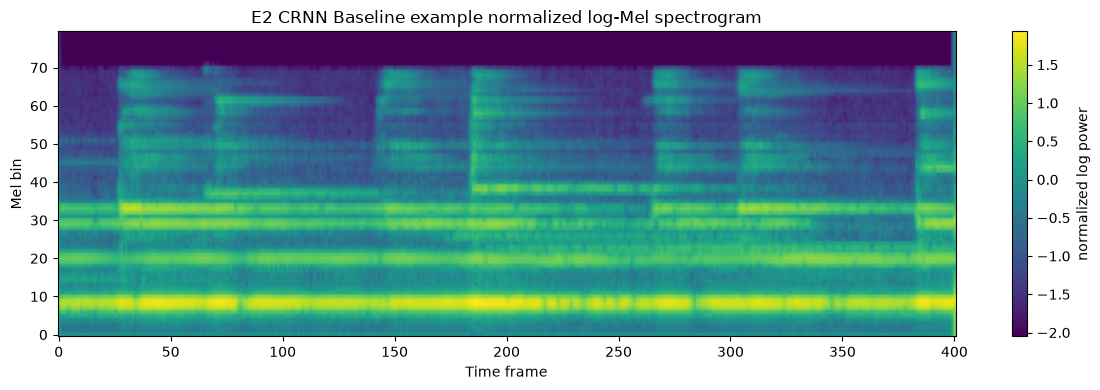

In [11]:
# 10. Visual sanity check for the GPU input representation

sample_row=train_run_df.iloc[0]

sample_path=audio_path_from_row(
    sample_row,
    PROJECT_ROOT
)

sample_wave=cpu_prepare_waveform(
    sample_path,
    sample_rate=SAMPLE_RATE,
    segment_seconds=SEGMENT_SECONDS,
    training=False
)

sample_batch=sample_wave.unsqueeze(0).to(
    DEVICE,
    non_blocking=True
)

with torch.no_grad():
    sample_logmel=gpu_logmel(
        sample_batch
    )

sample_logmel=normalize_log_mel(
    sample_logmel,
    MEL_MEAN,
    MEL_STD
)

sample_logmel=sample_logmel[0].cpu().numpy()

print("Audio:",sample_path.name)
print("Type:",sample_row["type"])
print("Label:",sample_row["label"])
print("Generator:",sample_row["generator"])
print("Waveform shape:",sample_wave.shape)
print("Log-Mel shape:",sample_logmel.shape)

plt.figure(figsize=(12,4))
plt.imshow(
    sample_logmel,
    origin="lower",
    aspect="auto"
)
plt.title("E2 CRNN Baseline example normalized log-Mel spectrogram")
plt.xlabel("Time frame")
plt.ylabel("Mel bin")
plt.colorbar(label="normalized log power")
plt.tight_layout()
plt.show()

In [12]:
# 11. Build the training and development DataLoaders

train_loader=make_waveform_loader(train_run_df,True)

train_eval_loader=make_waveform_loader(train_run_df,False)

dev_loader=make_waveform_loader(dev_run_df,False)

print("Training batches:",len(train_loader))
print("Training evaluation batches:",len(train_eval_loader))
print("Development batches:",len(dev_loader))

Training batches: 1875
Training evaluation batches: 1875
Development batches: 705


In [13]:
# 12. Build MobileNetV3-Small + GRU compact CRNN

class MobileNetV3SmallGRUAudio(nn.Module):
    def __init__(
        self,
        num_classes=2,
        gru_hidden_size=128,
        gru_layers=1,
        dropout=0.2
    ):
        super().__init__()

        backbone = mobilenet_v3_small(weights=None)

        # Replace RGB 3-channel conv1 with single-channel conv1
        old_conv = backbone.features[0][0]
        new_conv = nn.Conv2d(
            in_channels=1,
            out_channels=old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            dilation=old_conv.dilation,
            groups=old_conv.groups,
            bias=False
        )
        backbone.features[0][0] = new_conv

        # Retain convolutional feature extractor (576 channels output)
        self.feature_extractor = backbone.features
        self.feature_dim = backbone.classifier[0].in_features  # 576

        # Collapse ONLY the frequency dimension; preserve temporal sequence
        self.frequency_pool = nn.AdaptiveAvgPool2d((1, None))

        # Lightweight recurrent sequence encoder
        self.gru = nn.GRU(
            input_size=self.feature_dim,
            hidden_size=gru_hidden_size,
            num_layers=gru_layers,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(gru_hidden_size, num_classes)

        self.gru_hidden_size = gru_hidden_size
        self.gru_layers = gru_layers
        self.dropout_rate = dropout

    def extract_sequence(self, x):
        # [batch, 1, 80, time] -> [batch, 576, freq', time']
        x = self.feature_extractor(x)
        # Collapse frequency: [batch, 576, 1, time']
        x = self.frequency_pool(x)
        # Remove singleton freq: [batch, 576, time']
        x = x.squeeze(2)
        # Transpose to sequence order: [batch, time', 576]
        x = x.transpose(1, 2)
        return x

    def forward(self, x):
        sequence = self.extract_sequence(x)
        _, hidden = self.gru(sequence)
        # Final hidden state summarizes temporal acoustic context: [batch, gru_hidden_size]
        representation = hidden[-1]
        logits = self.classifier(self.dropout(representation))
        return logits


model = MobileNetV3SmallGRUAudio(
    num_classes=2,
    gru_hidden_size=GRU_HIDDEN_SIZE,
    gru_layers=GRU_LAYERS,
    dropout=CLASSIFIER_DROPOUT
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 60)
print(f"E2 Architecture: MobileNetV3-Small + GRU (Hidden: {GRU_HIDDEN_SIZE}, Layers: {GRU_LAYERS})")
print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("=" * 60)

E2 Architecture: MobileNetV3-Small + GRU (Hidden: 128, Layers: 1)
Total parameters:     1,198,082
Trainable parameters: 1,198,082


# 13. Loss function and optimizer

E2 uses class-weighted cross-entropy, with class weights computed from the training partition.

The optimizer is AdamW with a small weight decay. A `ReduceLROnPlateau` scheduler reduces the learning rate when development Macro-F1 stops improving.

The development set is used for model selection; the evaluation set is not used to choose the model.


In [14]:
# 13. Loss and optimizer (Class-Weighted Cross-Entropy)

# Compute inverse frequency class weights to balance 44,000 fake vs 16,000 real training clips
class_counts = train_run_df["label"].map(LABEL_MAP).value_counts().sort_index()
total_samples = len(train_run_df)

# Balanced weight formula: w_c = N / (C * N_c)
class_weights = total_samples / (2.0 * class_counts.values.astype(np.float32))
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Learning rate scheduler that adapts during extended 35-epoch training (no verbose argument)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

print(f"Training Class Counts (0=Real, 1=Fake): {dict(class_counts)}")
print(f"Class Weights (Real, Fake)            : {class_weights}")
print(f"Loss Function                          : CrossEntropyLoss(weight={class_weights_tensor.cpu().numpy()})")

Training Class Counts (0=Real, 1=Fake): {0: np.int64(16000), 1: np.int64(44000)}
Class Weights (Real, Fake)            : [1.875     0.6818182]
Loss Function                          : CrossEntropyLoss(weight=[1.875     0.6818182])


# 14. Evaluation metrics

The main E2 metrics are:

### Macro-F1

Macro-F1 calculates F1 separately for real and fake classes and then averages them. This prevents the larger class from dominating the summary score.

### AUROC

AUROC measures how well the model ranks fake and real examples across decision thresholds.

### EER

Equal Error Rate is calculated from the ROC curve by finding the point where false-positive and false-negative rates are approximately equal.

Accuracy is also recorded, but it is not the primary metric for comparing the detector.


In [15]:
# 14. Evaluation metrics (compute_eer, calculate_metrics, waveform_batch_to_features, run_evaluation)

def compute_eer(y_true, scores):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    if len(np.unique(y_true)) < 2:
        return float("nan"), float("nan")
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    fnr = 1.0 - tpr
    index = np.nanargmin(np.abs(fpr - fnr))
    eer = float((fpr[index] + fnr[index]) / 2.0)
    threshold = float(thresholds[index])
    return eer, threshold

def calculate_metrics(y_true, scores, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores).astype(float)
    if len(y_true) == 0:
        raise ValueError("Cannot calculate metrics on an empty dataset.")
    predictions = (scores >= threshold).astype(int)
    metrics = {
        "macro_f1": float(f1_score(y_true, predictions, average="macro", zero_division=0)),
        "accuracy": float(accuracy_score(y_true, predictions)),
        "auroc": float("nan")
    }
    if len(np.unique(y_true)) == 2:
        metrics["auroc"] = float(roc_auc_score(y_true, scores))
    eer, eer_threshold = compute_eer(y_true, scores)
    metrics["eer"] = eer
    metrics["eer_threshold"] = eer_threshold
    return metrics, predictions

@torch.no_grad()
def waveform_batch_to_features(waveforms):
    waveforms = waveforms.to(DEVICE, non_blocking=True)
    log_mel = gpu_logmel(waveforms)
    log_mel = normalize_log_mel(log_mel, MEL_MEAN, MEL_STD)
    return log_mel.unsqueeze(1)

@torch.no_grad()
def run_evaluation(model, loader, criterion=None, description="Evaluating"):
    model.eval()
    total_loss = 0.0
    total_items = 0
    all_labels = []
    all_scores = []
    all_file_ids = []
    for waveforms, y, file_ids in tqdm(loader, desc=description, leave=False):
        y = y.to(DEVICE, non_blocking=True)
        x = waveform_batch_to_features(waveforms)
        with autocast_context():
            logits = model(x)
            if criterion is not None:
                loss = criterion(logits, y)
        if criterion is not None:
            total_loss += float(loss.item()) * x.size(0)
        scores = torch.softmax(logits.float(), dim=1)[:, 1]
        all_labels.extend(y.cpu().numpy().tolist())
        all_scores.extend(scores.float().cpu().numpy().tolist())
        all_file_ids.extend(list(file_ids))
        total_items += x.size(0)
    avg_loss = total_loss / max(total_items, 1)
    metrics, predictions = calculate_metrics(all_labels, all_scores)
    metrics["loss"] = avg_loss
    return metrics, np.asarray(all_labels), np.asarray(all_scores), predictions, all_file_ids

## GPU training and GPU feature extraction

CPU DataLoader workers handle audio decoding, resampling and crop/repeat-padding. Batched STFT, Mel extraction, log compression and normalization run on the GPU when CUDA is available.

In [16]:
# 15. Mixed-precision training setup

amp_enabled=DEVICE.type=="cuda"

scaler=torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

def autocast_context():
    return torch.amp.autocast(
        device_type=DEVICE.type,
        dtype=torch.float16,
        enabled=amp_enabled
    )

# 16. Training loop

The model is trained on the training partition and evaluated on the development partition after every epoch.

The best checkpoint is selected using **development Macro-F1**.

Training runs for the full 35 epochs without early stopping, preserving the best checkpoint achieved on development Macro-F1.

The evaluation partition is not used during model selection.

In [17]:
# 16. Train one epoch with gradient clipping

def train_one_epoch(model, loader):
    model.train()
    running_loss = 0.0
    correct = 0
    total_items = 0
    grad_norms = []

    progress = tqdm(loader, desc="Training", leave=False)

    for waveforms, y, _ in progress:
        y = y.to(DEVICE, non_blocking=True)
        x = waveform_batch_to_features(waveforms)

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits = model(x)
            loss = criterion(logits, y)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)                                              # 1. unscale first
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)  # 2. then clip
        if torch.isfinite(gn):
            grad_norms.append(float(gn))
        scaler.step(optimizer)                                                  # 3. step skips inf/nan automatically
        scaler.update()

        predictions = torch.argmax(logits, dim=1)
        correct += (predictions == y).sum().item()
        running_loss += float(loss.item()) * x.size(0)
        total_items += x.size(0)

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = running_loss / max(total_items, 1)
    train_accuracy = correct / max(total_items, 1)
    gn_med = float(np.median(grad_norms)) if grad_norms else 0.0
    gn_p99 = float(np.percentile(grad_norms, 99)) if grad_norms else 0.0

    return train_loss, train_accuracy, gn_med, gn_p99

In [18]:
# 17. Train E2 Hybrid CRNN to Convergence (35 Epochs, Multi-Seed Protocol)

history = []
best_dev_f1 = -np.inf
best_epoch = -1
epochs_without_improvement = 0

best_checkpoint_path = CHECKPOINT_DIR / f"E2_MobileNetV3Small_GRU_ATADD_best_{SEED_TAG}.pt"
history_path = EXPERIMENT_DIR / f"E2_ATADD_training_history_{SEED_TAG}.csv"

print(f"Starting E2 Hybrid CRNN ({SEED_TAG}, seed={SEED}) training for {EPOCHS} epochs (Early stopping disabled, Max Grad Norm: {MAX_GRAD_NORM})...")

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()
    train_loss, train_accuracy, gn_med, gn_p99 = train_one_epoch(model, train_loader)
    dev_metrics, dev_y, dev_scores, dev_preds, dev_ids = run_evaluation(model, dev_loader, criterion)

    # Step scheduler based on Dev Macro-F1
    scheduler.step(dev_metrics["macro_f1"])
    epoch_time = time.time() - start_time

    row = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "train_accuracy": float(train_accuracy),
        "grad_norm_median": float(gn_med),
        "grad_norm_p99": float(gn_p99),
        "dev_loss": float(dev_metrics["loss"]),
        "dev_accuracy": float(dev_metrics["accuracy"]),
        "dev_macro_f1": float(dev_metrics["macro_f1"]),
        "dev_auroc": float(dev_metrics["auroc"]),
        "dev_eer": float(dev_metrics["eer"]),
        "lr": float(optimizer.param_groups[0]["lr"]),
        "epoch_seconds": float(epoch_time),
        "seed_tag": SEED_TAG,
        "seed": SEED
    }
    history.append(row)

    history_df = pd.DataFrame(history)
    history_df.to_csv(history_path, index=False)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} [{epoch_time:.1f}s] | "
        f"Train Loss: {train_loss:.4f} Acc: {train_accuracy:.4f} | "
        f"GN(med/p99): {gn_med:.2f}/{gn_p99:.2f} | "
        f"Dev Loss: {dev_metrics['loss']:.4f} Acc: {dev_metrics['accuracy']:.4f} "
        f"F1: {dev_metrics['macro_f1']:.4f} AUROC: {dev_metrics['auroc']:.4f} EER: {dev_metrics['eer']*100:.2f}% | "
        f"LR: {optimizer.param_groups[0]['lr']:.2e}"
    )

    if dev_metrics["macro_f1"] > best_dev_f1:
        best_dev_f1 = dev_metrics["macro_f1"]
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save(
            {
                "experiment": f"E2_ATADD_Reworked_{SEED_TAG}",
                "experiment_version": EXPERIMENT_VERSION,
                "input_preprocessing_version": INPUT_PREPROCESSING_VERSION,
                "model_name": "MobileNetV3-Small + GRU",
                "model_config": {
                    "num_classes": 2,
                    "gru_hidden_size": GRU_HIDDEN_SIZE,
                    "gru_layers": GRU_LAYERS,
                    "classifier_dropout": CLASSIFIER_DROPOUT
                },
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "dev_metrics": dev_metrics,
                "seed_tag": SEED_TAG,
                "seed": SEED,
                "max_grad_norm": MAX_GRAD_NORM,
                "class_weights": class_weights.tolist()
            },
            best_checkpoint_path
        )
        print(f"  -> Best Dev Macro-F1: {best_dev_f1:.6f} saved to {best_checkpoint_path.name}")
    else:
        epochs_without_improvement += 1
        print(f"  -> No improvement for {epochs_without_improvement} epoch(s)")

print(f"\nTraining complete! Best checkpoint: {best_checkpoint_path} (Epoch {best_epoch}, Dev Macro-F1: {best_dev_f1:.6f})")

Starting E2 Hybrid CRNN (seed1, seed=42) training for 25 epochs (Early stopping disabled, Max Grad Norm: 5.0)...


Epoch 01/25 [126.3s] | Train Loss: 0.3173 Acc: 0.8605 | GN(med/p99): 4.10/17.04 | Dev Loss: 0.8850 Acc: 0.7128 F1: 0.6569 AUROC: 0.7198 EER: 35.39% | LR: 1.00e-03
  -> Best Dev Macro-F1: 0.656857 saved to E2_MobileNetV3Small_GRU_ATADD_best_seed1.pt


Epoch 02/25 [125.1s] | Train Loss: 0.1616 Acc: 0.9375 | GN(med/p99): 3.28/14.41 | Dev Loss: 1.3869 Acc: 0.5599 F1: 0.5596 AUROC: 0.7914 EER: 28.04% | LR: 1.00e-03
  -> No improvement for 1 epoch(s)


Epoch 03/25 [119.9s] | Train Loss: 0.1193 Acc: 0.9539 | GN(med/p99): 2.42/14.00 | Dev Loss: 1.2037 Acc: 0.6025 F1: 0.5991 AUROC: 0.8155 EER: 25.83% | LR: 1.00e-03
  -> No improvement for 2 epoch(s)


Epoch 04/25 [122.4s] | Train Loss: 0.0960 Acc: 0.9645 | GN(med/p99): 1.87/12.08 | Dev Loss: 1.1314 Acc: 0.6676 F1: 0.6595 AUROC: 0.8614 EER: 21.69% | LR: 1.00e-03
  -> Best Dev Macro-F1: 0.659457 saved to E2_MobileNetV3Small_GRU_ATADD_best_seed1.pt


...

Epoch 21/25 [117.4s] | Train Loss: 0.0063 Acc: 0.9980 | GN(med/p99): 0.03/7.81 | Dev Loss: 2.4350 Acc: 0.6271 F1: 0.6237 AUROC: 0.8611 EER: 21.08% | LR: 6.25e-05
  -> No improvement for 17 epoch(s)


Epoch 22/25 [119.2s] | Train Loss: 0.0070 Acc: 0.9978 | GN(med/p99): 0.03/10.01 | Dev Loss: 2.3456 Acc: 0.6314 F1: 0.6267 AUROC: 0.8514 EER: 22.61% | LR: 6.25e-05
  -> No improvement for 18 epoch(s)


Epoch 23/25 [117.2s] | Train Loss: 0.0061 Acc: 0.9978 | GN(med/p99): 0.02/7.51 | Dev Loss: 2.5717 Acc: 0.6171 F1: 0.6143 AUROC: 0.8546 EER: 21.90% | LR: 6.25e-05
  -> No improvement for 19 epoch(s)


Epoch 24/25 [123.0s] | Train Loss: 0.0052 Acc: 0.9982 | GN(med/p99): 0.01/8.72 | Dev Loss: 2.6352 Acc: 0.6305 F1: 0.6259 AUROC: 0.8422 EER: 22.88% | LR: 3.13e-05
  -> No improvement for 20 epoch(s)


Epoch 25/25 [120.2s] | Train Loss: 0.0049 Acc: 0.9984 | GN(med/p99): 0.01/8.10 | Dev Loss: 2.6761 Acc: 0.6257 F1: 0.6214 AUROC: 0.8453 EER: 22.42% | LR: 3.13e-05
  -> No improvement for 21 epoch(s)

Training complete! Best checkpoint: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/checkpoints/reworked/E2/E2_MobileNetV3Small_GRU_ATADD_best_seed1.pt (Epoch 4, Dev Macro-F1: 0.659457)


## Training curves

The training curves provide a quick way to identify:

- underfitting
- overfitting
- unstable optimization
- whether the development performance has stopped improving

These plots are saved under `results/figures/` for the project record.

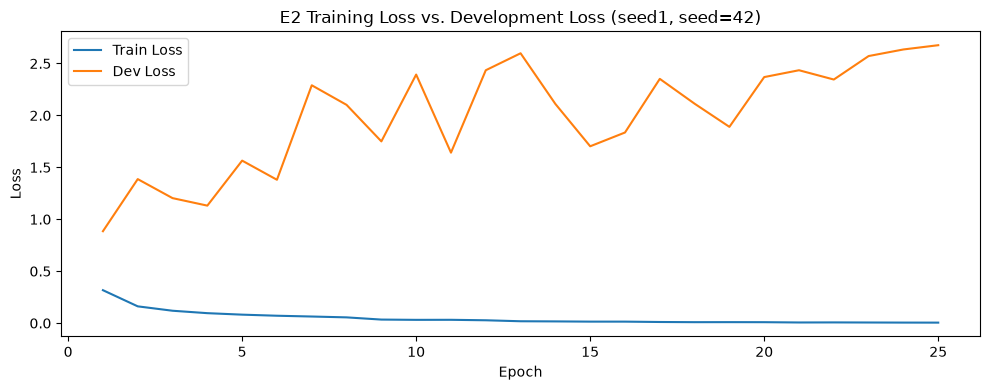

Saved training curves to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/reworked/E2/E2_ATADD_training_curves_seed1.png


In [19]:
# 18. Plot and save training curves

plt.figure(figsize=(10, 4))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train Loss")
plt.plot(history_df["epoch"], history_df["dev_loss"], label="Dev Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"E2 Training Loss vs. Development Loss ({SEED_TAG}, seed={SEED})")
plt.legend()
plt.tight_layout()

curves_path = RESULT_FIGURE_DIR / f"E2_ATADD_training_curves_{SEED_TAG}.png"
plt.savefig(curves_path, dpi=200)
plt.show()

print("Saved training curves to:", curves_path)

# 19. Final development evaluation

After training, we reload the checkpoint with the best development Macro-F1.

All reported development metrics below therefore correspond to the selected E2 checkpoint rather than simply the final training epoch.

In [20]:
checkpoint=torch.load(best_checkpoint_path,map_location=DEVICE,weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])

print(f"Loaded checkpoint for {SEED_TAG} from epoch:",checkpoint["epoch"])
print(f"Best development Macro-F1 ({SEED_TAG}):",checkpoint["dev_metrics"]["macro_f1"])

Loaded checkpoint for seed1 from epoch: 4
Best development Macro-F1 (seed1): 0.659457027337471


## Development-set results

These are the metrics we use to understand how well the clean E2 baseline learned the real/fake classification task.

The development predictions are also saved so that later analysis can inspect individual recordings.

In [21]:
# 20. Final development-set evaluation & Decision-Threshold Calibration

val_metrics_05, val_y, val_scores, val_preds_05, val_ids = run_evaluation(model, dev_loader, criterion)

# Sweep decision thresholds on the validation set to find optimal threshold theta*
candidate_thresholds = np.linspace(0.01, 0.99, 99)
sweep_records = []
best_dev_thresh = 0.50
best_dev_macro_f1 = -1.0

for t in candidate_thresholds:
    preds_t = (val_scores >= t).astype(int)
    f1_t = f1_score(val_y, preds_t, average="macro", zero_division=0)
    acc_t = accuracy_score(val_y, preds_t)
    bacc_t = balanced_accuracy_score(val_y, preds_t)
    if f1_t > best_dev_macro_f1:
        best_dev_macro_f1 = f1_t
        best_dev_thresh = float(t)
    sweep_records.append({
        "threshold": float(t),
        "macro_f1": float(f1_t),
        "accuracy": float(acc_t),
        "balanced_accuracy": float(bacc_t)
    })

dev_sweep_df = pd.DataFrame(sweep_records)
dev_sweep_path = EXPERIMENT_DIR / f"E2_ATADD_dev_threshold_sweep_{SEED_TAG}.csv"
dev_sweep_df.to_csv(dev_sweep_path, index=False)

# Compute metrics at the calibrated threshold
val_metrics_opt, val_preds_opt = calculate_metrics(val_y, val_scores, threshold=best_dev_thresh)
val_metrics_opt["loss"] = val_metrics_05["loss"]

print(f"=== E2 VALIDATION RESULTS ({SEED_TAG}) ===")
print(f"Fixed Default Threshold (theta = 0.50):")
print(f"  Macro-F1          : {val_metrics_05['macro_f1']:.6f}")
print(f"  Accuracy          : {val_metrics_05['accuracy']:.6f}")
print(f"  AUROC             : {val_metrics_05['auroc']:.6f}")
print(f"  EER               : {val_metrics_05['eer']*100:.2f}% (threshold={val_metrics_05['eer_threshold']:.4f})")
print(f"\nDev-Calibrated Threshold (theta* = {best_dev_thresh:.4f}):")
print(f"  Calibrated Macro-F1: {val_metrics_opt['macro_f1']:.6f} (Delta: {val_metrics_opt['macro_f1'] - val_metrics_05['macro_f1']:+.6f})")
print(f"  Calibrated Accuracy: {val_metrics_opt['accuracy']:.6f}")

val_metrics_all = {
    "fixed_0.5": val_metrics_05,
    "calibrated_dev": val_metrics_opt,
    "optimal_dev_threshold": best_dev_thresh
}

val_metrics_path = EXPERIMENT_DIR / f"E2_ATADD_validation_metrics_{SEED_TAG}.json"
with open(val_metrics_path, "w", encoding="utf-8") as f:
    json.dump(val_metrics_all, f, indent=2)

print("Saved validation metrics to:", val_metrics_path)

=== E2 VALIDATION RESULTS (seed1) ===
Fixed Default Threshold (theta = 0.50):
  Macro-F1          : 0.659457
  Accuracy          : 0.667643
  AUROC             : 0.861352
  EER               : 21.69% (threshold=0.0612)

Dev-Calibrated Threshold (theta* = 0.0100):
  Calibrated Macro-F1: 0.795477 (Delta: +0.136020)
  Calibrated Accuracy: 0.839723
Saved validation metrics to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E2/E2_ATADD_validation_metrics_seed1.json


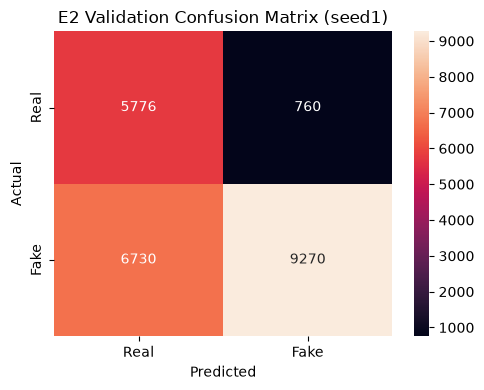

Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/reworked/E2/E2_ATADD_validation_confusion_matrix_seed1.png


In [22]:
# 21. Validation confusion matrix

cm = confusion_matrix(val_y, val_preds_05)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Real", "Fake"],
    yticklabels=["Real", "Fake"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"E2 Validation Confusion Matrix ({SEED_TAG})")
plt.tight_layout()

val_cm_path = RESULT_FIGURE_DIR / f"E2_ATADD_validation_confusion_matrix_{SEED_TAG}.png"
plt.savefig(val_cm_path, dpi=200)
plt.show()

print("Saved:", val_cm_path)

## Save development predictions

Saving the individual prediction scores is useful later when comparing E1 with E2/E3 or investigating difficult examples.

The file contains the model's fake score, predicted class and ground-truth label for each development recording.

In [23]:
# 22. Save validation predictions for later analysis

val_output = pd.DataFrame({
    "file_id": val_ids,
    "label": val_y,
    "spoof_score": val_scores,
    "prediction_05": (val_scores >= 0.5).astype(int),
    "prediction_opt": (val_scores >= best_dev_thresh).astype(int),
    "seed_tag": SEED_TAG,
    "seed": SEED
})

val_output_path = EXPERIMENT_DIR / f"E2_ATADD_val_predictions_{SEED_TAG}.csv"
val_output.to_csv(val_output_path, index=False)
print("Saved validation predictions to:", val_output_path)

Saved validation predictions to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E2/E2_ATADD_val_predictions_seed1.csv


# 23. Official evaluation inference

The official evaluation partition is processed only after the E2 checkpoint has been selected using the development set.

If evaluation labels are available, the notebook calculates the same metrics used on the development set.

If labels are not available, it saves prediction scores without inventing evaluation metrics.

In [24]:
# 23. Prepare the official evaluation DataLoader

eval_scores=np.asarray([])
eval_labels=np.asarray([])
eval_ids=[]
eval_analysis=pd.DataFrame()

if len(eval_run_df):
    eval_loader=make_waveform_loader(
        eval_run_df,
        False
    )
else:
    eval_loader=None

print(
    "Evaluation loader ready:",
    eval_loader is not None
)

Evaluation loader ready: True


In [25]:
# 24. Run official evaluation inference (Dual Thresholds: Fixed 0.5 & Dev-Calibrated theta*)

if len(eval_run_df):
    model.eval()
    eval_scores = []
    eval_labels = []
    eval_ids = []

    with torch.no_grad():
        for waveforms, y, file_ids in tqdm(eval_loader, desc=f"Official evaluation ({SEED_TAG})"):
            y = y.to(DEVICE, non_blocking=True)
            x = waveform_batch_to_features(waveforms)
            with autocast_context():
                logits = model(x)
            scores = torch.softmax(logits.float(), dim=1)[:, 1]
            eval_scores.extend(scores.float().cpu().numpy().tolist())
            eval_labels.extend(y.cpu().numpy().tolist())
            eval_ids.extend(list(file_ids))

    eval_scores = np.asarray(eval_scores)
    eval_labels = np.asarray(eval_labels)

    # Compute predictions at BOTH thresholds
    eval_predictions_05 = (eval_scores >= 0.5).astype(int)
    eval_predictions_opt = (eval_scores >= best_dev_thresh).astype(int)

    eval_output = pd.DataFrame({
        "file_id": eval_ids,
        "label": eval_labels,
        "spoof_score": eval_scores,
        "prediction": eval_predictions_05,        # Default 0.5
        "prediction_05": eval_predictions_05,     # Explicit 0.5
        "prediction_opt": eval_predictions_opt,   # Dev-selected theta*
        "seed_tag": SEED_TAG,
        "seed": SEED
    })

    eval_output_path = EXPERIMENT_DIR / f"E2_ATADD_eval_predictions_{SEED_TAG}.csv"
    eval_output.to_csv(eval_output_path, index=False)
    print("Saved evaluation predictions to:", eval_output_path)

    if len(np.unique(eval_labels)) == 2:
        eval_metrics_05, _ = calculate_metrics(eval_labels, eval_scores, threshold=0.5)
        eval_metrics_opt, _ = calculate_metrics(eval_labels, eval_scores, threshold=best_dev_thresh)

        print(f"\n=== OFFICIAL AT-ADD EVALUATION RESULTS ({SEED_TAG}) ===")
        print(f"--- 1. Default Threshold (theta = 0.50) ---")
        for k, v in eval_metrics_05.items():
            print(f"  {k:<16}: {v:.6f}")

        print(f"\n--- 2. Dev-Calibrated Threshold (theta* = {best_dev_thresh:.4f}) ---")
        for k, v in eval_metrics_opt.items():
            print(f"  {k:<16}: {v:.6f}")

        eval_comparison_summary = {
            "fixed_threshold_0.5": eval_metrics_05,
            "dev_calibrated_threshold": eval_metrics_opt,
            "calibrated_threshold_value": best_dev_thresh
        }

        eval_metrics_path = EXPERIMENT_DIR / f"E2_ATADD_eval_metrics_{SEED_TAG}.json"
        with open(eval_metrics_path, "w", encoding="utf-8") as f:
            json.dump(eval_comparison_summary, f, indent=2)
        print("Saved dual-threshold metrics to:", eval_metrics_path)
    else:
        print("\nEvaluation labels do not contain both classes.")
else:
    print("No evaluation manifest was found.")

Official evaluation (seed1): 100%|██████████| 1385/1385 [01:02<00:00, 22.22it/s]

Saved evaluation predictions to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E2/E2_ATADD_eval_predictions_seed1.csv

=== OFFICIAL AT-ADD EVALUATION RESULTS (seed1) ===
--- 1. Default Threshold (theta = 0.50) ---
  macro_f1        : 0.528175
  accuracy        : 0.567839
  auroc           : 0.821871
  eer             : 0.246595
  eer_threshold   : 0.030821

--- 2. Dev-Calibrated Threshold (theta* = 0.0100) ---
  macro_f1        : 0.667034
  accuracy        : 0.790919
  auroc           : 0.821871
  eer             : 0.246595
  eer_threshold   : 0.030821
Saved dual-threshold metrics to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E2/E2_ATADD_eval_metrics_seed1.json


DUAL-THRESHOLD GENERALIZATION AUDIT (seed1)
Thresholds: Default theta=0.50  vs.  Dev-Calibrated theta*=0.0100

[A] Per-Type Domain Breakdown (4 Domains)
----------------------------------------------------------------------


,Domain,Total Samples,Real Samples,Fake Samples,Macro-F1 (0.50),Macro-F1 (theta*),Delta F1,AUROC,EER (%)
0,Speech,27000,2000,25000,0.539828,0.668955,0.129127,0.867966,20.247000
1,Sound,6000,2000,4000,0.439154,0.559024,0.119871,0.657242,41.512500
2,Singing,6753,2000,4753,0.398252,0.752077,0.353825,0.852847,22.095655
3,Music,4536,536,4000,0.309269,0.402458,0.093188,0.480269,51.677052


Type-Averaged Macro-F1 at theta=0.50   : 0.421626
Type-Averaged Macro-F1 at theta*=0.01: 0.595628 (Delta: +0.174003)
Saved domain breakdown to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E2/E2_ATADD_eval_type_results_seed1.csv

[B] Per-Generator Breakdown on 38 Unseen Fake Generators
----------------------------------------------------------------------


,Generator,Domain,Samples,Recall (0.50),Recall (theta*),Delta Recall,Mean Spoof Score
26,SSM-TTM,music,1000,0.000000,0.012000,0.012000,0.000993
0,ACE-Step,music,1000,0.020000,0.221000,0.201000,0.035119
1,Auffusion,sound,1000,0.047000,0.293000,0.246000,0.065719
21,MeanAudio,sound,1000,0.130000,0.332000,0.202000,0.137686
25,RVC-FSD,singing,753,0.066401,0.602922,0.536521,0.110633
2,BigVGAN,speech,1000,0.186000,0.652000,0.466000,0.202289
34,UniAudio2,sound,1000,0.349000,0.698000,0.349000,0.354883
36,VEVO1.5,singing,1000,0.047000,0.717000,0.670000,0.100857
19,Llasa8B,speech,1000,0.233000,0.736000,0.503000,0.254936
18,Llasa3B,speech,1000,0.253000,0.740000,0.487000,0.278861


... and 23 more generators.
Saved generator breakdown to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E2/E2_ATADD_eval_generator_results_seed1.csv

[C] Real Audio: Seen vs. Unseen Source Breakdown
----------------------------------------------------------------------


,Source Category,Clips,Real Acc (0.50),False Alarm (0.50),Real Acc (theta*),False Alarm (theta*),Mean Spoof Score
0,Seen Source,4864,94.08%,5.92%,67.74%,32.26%,0.074696
1,Unseen Source,1672,94.38%,5.62%,42.58%,57.42%,0.081644


Saved real source breakdown to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E2/eval_real_source_breakdown_seed1.csv


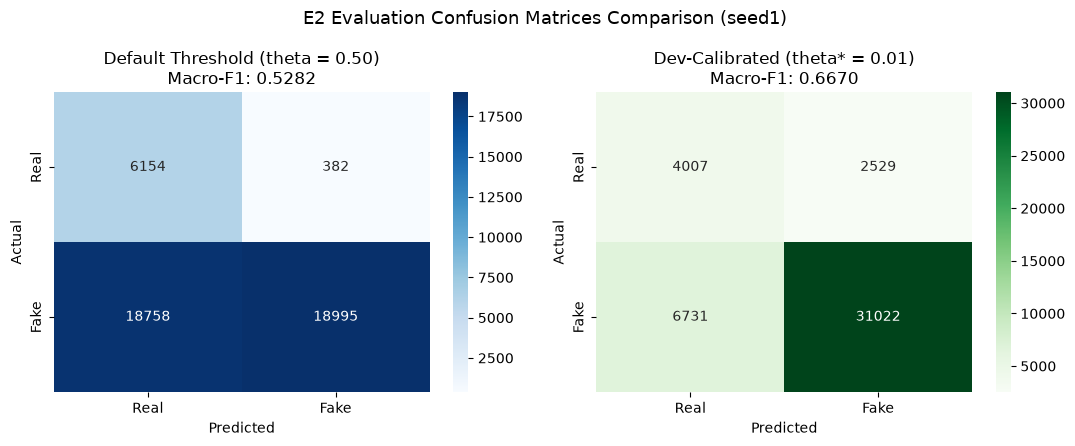

Saved dual confusion matrix figure to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/reworked/E2/E2_ATADD_eval_confusion_matrix_seed1.png


In [26]:
# 24.5. Dual-Threshold Generalization Analysis: Per-Type, Per-Generator, & Seen vs Unseen Real Sources

if len(eval_run_df) and len(eval_scores):
    eval_analysis = eval_run_df[
        [
            "file_id",
            "type",
            "label",
            "generator",
            "source"
        ]
    ].copy()

    eval_analysis["label_id"] = eval_analysis["label"].map(LABEL_MAP)
    eval_analysis["spoof_score"] = eval_scores
    eval_analysis["prediction_05"] = (eval_scores >= 0.5).astype(int)
    eval_analysis["prediction_opt"] = (eval_scores >= best_dev_thresh).astype(int)
    eval_analysis["prediction"] = eval_analysis["prediction_05"]

    print("======================================================================")
    print(f"DUAL-THRESHOLD GENERALIZATION AUDIT ({SEED_TAG})")
    print(f"Thresholds: Default theta=0.50  vs.  Dev-Calibrated theta*={best_dev_thresh:.4f}")
    print("======================================================================")

    # -------------------------------------------------------------------------
    # A. Per-Type Domain Breakdown at BOTH Thresholds
    # -------------------------------------------------------------------------
    print(f"\n[A] Per-Type Domain Breakdown (4 Domains)")
    print("-" * 70)
    type_results = []
    for audio_type in ["speech", "sound", "singing", "music"]:
        subset = eval_analysis[eval_analysis["type"] == audio_type]
        if len(subset) == 0:
            continue
        y_true = subset["label_id"].to_numpy()
        scores = subset["spoof_score"].to_numpy()
        if len(np.unique(y_true)) < 2:
            continue

        metrics_05, _ = calculate_metrics(y_true, scores, threshold=0.5)
        metrics_opt, _ = calculate_metrics(y_true, scores, threshold=best_dev_thresh)

        type_results.append({
            "Domain": audio_type.capitalize(),
            "Total Samples": len(subset),
            "Real Samples": int((y_true == 0).sum()),
            "Fake Samples": int((y_true == 1).sum()),
            "Macro-F1 (0.50)": metrics_05["macro_f1"],
            "Macro-F1 (theta*)": metrics_opt["macro_f1"],
            "Delta F1": metrics_opt["macro_f1"] - metrics_05["macro_f1"],
            "AUROC": metrics_05["auroc"],
            "EER (%)": metrics_05["eer"] * 100.0
        })

    type_results_df = pd.DataFrame(type_results)
    display(type_results_df)

    type_avg_f1_05 = type_results_df["Macro-F1 (0.50)"].mean()
    type_avg_f1_opt = type_results_df["Macro-F1 (theta*)"].mean()
    print(f"Type-Averaged Macro-F1 at theta=0.50   : {type_avg_f1_05:.6f}")
    print(f"Type-Averaged Macro-F1 at theta*={best_dev_thresh:.2f}: {type_avg_f1_opt:.6f} (Delta: {type_avg_f1_opt - type_avg_f1_05:+.6f})")

    type_results_path = EXPERIMENT_DIR / f"E2_ATADD_eval_type_results_{SEED_TAG}.csv"
    type_results_df.to_csv(type_results_path, index=False)
    table_path = RESULT_TABLE_DIR / f"eval_domain_summary_{SEED_TAG}.csv"
    type_results_df.to_csv(table_path, index=False)
    print("Saved domain breakdown to:", type_results_path)

    # -------------------------------------------------------------------------
    # B. Per-Generator Breakdown on Fake Samples at BOTH Thresholds
    # -------------------------------------------------------------------------
    print(f"\n[B] Per-Generator Breakdown on 38 Unseen Fake Generators")
    print("-" * 70)
    fake_eval = eval_analysis[eval_analysis["label"] == "fake"]
    generator_results = []

    for generator, group in fake_eval.groupby("generator"):
        if generator == "-" or pd.isna(generator):
            continue
        scores = group["spoof_score"].to_numpy()
        preds_05 = group["prediction_05"].to_numpy()
        preds_opt = group["prediction_opt"].to_numpy()

        det_05 = int((preds_05 == 1).sum())
        det_opt = int((preds_opt == 1).sum())
        total = len(group)

        generator_results.append({
            "Generator": generator,
            "Domain": group["type"].mode().iloc[0],
            "Samples": total,
            "Recall (0.50)": det_05 / total,
            "Recall (theta*)": det_opt / total,
            "Delta Recall": (det_opt - det_05) / total,
            "Mean Spoof Score": float(scores.mean())
        })

    generator_results_df = pd.DataFrame(generator_results).sort_values("Recall (theta*)")
    display(generator_results_df.head(15))
    print(f"... and {len(generator_results_df) - 15} more generators.")

    gen_path = EXPERIMENT_DIR / f"E2_ATADD_eval_generator_results_{SEED_TAG}.csv"
    generator_results_df.to_csv(gen_path, index=False)
    print("Saved generator breakdown to:", gen_path)

    # -------------------------------------------------------------------------
    # C. Real Audio: Seen vs. Unseen Real Source Breakdown at BOTH Thresholds
    # -------------------------------------------------------------------------
    print(f"\n[C] Real Audio: Seen vs. Unseen Source Breakdown")
    print("-" * 70)
    seen_sources = set(train_df.loc[train_df["label"] == "real", "source"]) | set(dev_df.loc[dev_df["label"] == "real", "source"])
    real_eval = eval_analysis[eval_analysis["label"] == "real"].copy()
    real_eval["source_category"] = real_eval["source"].apply(
        lambda s: "Seen Source" if s in seen_sources else "Unseen Source"
    )

    real_source_results = []
    for cat, group in real_eval.groupby("source_category"):
        total = len(group)
        correct_05 = int((group["prediction_05"] == 0).sum())
        fp_05 = int((group["prediction_05"] == 1).sum())

        correct_opt = int((group["prediction_opt"] == 0).sum())
        fp_opt = int((group["prediction_opt"] == 1).sum())

        real_source_results.append({
            "Source Category": cat,
            "Clips": total,
            "Real Acc (0.50)": f"{correct_05 / total * 100:.2f}%",
            "False Alarm (0.50)": f"{fp_05 / total * 100:.2f}%",
            "Real Acc (theta*)": f"{correct_opt / total * 100:.2f}%",
            "False Alarm (theta*)": f"{fp_opt / total * 100:.2f}%",
            "Mean Spoof Score": float(group["spoof_score"].mean())
        })

    real_source_df = pd.DataFrame(real_source_results)
    display(real_source_df)

    real_source_path = EXPERIMENT_DIR / f"eval_real_source_breakdown_{SEED_TAG}.csv"
    real_source_df.to_csv(real_source_path, index=False)
    print("Saved real source breakdown to:", real_source_path)

    # -------------------------------------------------------------------------
    # D. Side-by-Side Confusion Matrices
    # -------------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    cm_05 = confusion_matrix(eval_labels, eval_analysis["prediction_05"].to_numpy())
    sns.heatmap(cm_05, annot=True, fmt="d", cmap="Blues", ax=axes[0],
                xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
    axes[0].set_title(f"Default Threshold (theta = 0.50)\nMacro-F1: {eval_metrics_05['macro_f1']:.4f}")
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")

    cm_opt = confusion_matrix(eval_labels, eval_analysis["prediction_opt"].to_numpy())
    sns.heatmap(cm_opt, annot=True, fmt="d", cmap="Greens", ax=axes[1],
                xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
    axes[1].set_title(f"Dev-Calibrated (theta* = {best_dev_thresh:.2f})\nMacro-F1: {eval_metrics_opt['macro_f1']:.4f}")
    axes[1].set_xlabel("Predicted")
    axes[1].set_ylabel("Actual")

    plt.suptitle(f"E2 Evaluation Confusion Matrices Comparison ({SEED_TAG})", fontsize=13)
    plt.tight_layout()
    eval_cm_path = RESULT_FIGURE_DIR / f"E2_ATADD_eval_confusion_matrix_{SEED_TAG}.png"
    plt.savefig(eval_cm_path, dpi=200)
    plt.show()
    print("Saved dual confusion matrix figure to:", eval_cm_path)
else:
    print("Evaluation analysis is not available.")

In [27]:
# Evaluation failure-case analysis (at both thresholds)

if len(eval_analysis):
    for thresh_tag, col in [("0.50", "prediction_05"), ("calibrated", "prediction_opt")]:
        fn = eval_analysis[
            (eval_analysis["label"].isin(["fake", "spoof"])) &
            (eval_analysis[col] == 0)
        ].copy()
        fp = eval_analysis[
            (eval_analysis["label"].isin(["real", "bonafide"])) &
            (eval_analysis[col] == 1)
        ].copy()

        print(f"Threshold [{thresh_tag}]: False Negatives (Missed Spoofs) = {len(fn):,}, False Positives (False Alarms) = {len(fp):,}")

        failures = pd.concat([
            fn.assign(error_type="false_negative", eval_threshold=thresh_tag),
            fp.assign(error_type="false_positive", eval_threshold=thresh_tag)
        ])

        fail_path = EXPERIMENT_DIR / f"E2_ATADD_eval_failure_cases_{thresh_tag}_{SEED_TAG}.csv"
        failures.to_csv(fail_path, index=False)
        print(f"Saved {thresh_tag} failure cases to: {fail_path}")

    # Backward compatibility file
    default_failures = eval_analysis[
        ((eval_analysis["label"].isin(["fake", "spoof"])) & (eval_analysis["prediction_05"] == 0)) |
        ((eval_analysis["label"].isin(["real", "bonafide"])) & (eval_analysis["prediction_05"] == 1))
    ]
    compat_path = EXPERIMENT_DIR / f"E2_ATADD_eval_failure_cases_{SEED_TAG}.csv"
    default_failures.to_csv(compat_path, index=False)
    print("Saved default failure cases to:", compat_path)
else:
    print("Evaluation analysis is not available.")

Threshold [0.50]: False Negatives (Missed Spoofs) = 18,758, False Positives (False Alarms) = 382
Saved 0.50 failure cases to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E2/E2_ATADD_eval_failure_cases_0.50_seed1.csv
Threshold [calibrated]: False Negatives (Missed Spoofs) = 6,731, False Positives (False Alarms) = 2,529
Saved calibrated failure cases to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E2/E2_ATADD_eval_failure_cases_calibrated_seed1.csv
Saved default failure cases to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E2/E2_ATADD_eval_failure_cases_seed1.csv


### Evaluation analysis note

The AT-ADD generator/type analysis is performed in the previous cell.

No speaker-overlap claim is made here because Track 2 metadata uses `-` for some identity fields by design. The primary generalization criterion for this E2 evaluation is the verified unseen-generator split.

# 25. Save the E2 experiment configuration

The final configuration records the model, preprocessing, dataset preparation version and training settings.

This is important because later changes to preprocessing or model design should produce a new experiment version rather than silently changing the meaning of E2.

In [28]:
# 25. Save the complete E2 Reworked AT-ADD configuration

config = {
    "experiment": f"E2_ATADD_Reworked_{SEED_TAG}",
    "seed_tag": SEED_TAG,
    "seed": SEED,
    "experiment_version": EXPERIMENT_VERSION,
    "input_preprocessing_version": INPUT_PREPROCESSING_VERSION,
    "preprocessing_module": "src/preprocessing/preprocess_atadd_rerun.py",
    "dataset_preparation_version": "AT-ADD_reworked_v1",
    "model": {
        "name": "MobileNetV3-Small + GRU",
        "weights": "scratch",
        "input_channels": 1,
        "num_classes": 2,
        "gru_hidden_size": GRU_HIDDEN_SIZE,
        "gru_layers": GRU_LAYERS,
        "classifier_dropout": CLASSIFIER_DROPOUT,
        "total_parameters": total_params,
        "trainable_parameters": trainable_params
    },
    "dataset": {
        "name": "AT-ADD Track 2 (Speaker-and-Generator-Disjoint)",
        "train_manifest": str(TRAIN_MANIFEST),
        "dev_manifest": str(DEV_MANIFEST),
        "eval_manifest": str(EVAL_MANIFEST),
        "train_samples": len(train_run_df),
        "dev_samples": len(dev_run_df),
        "eval_samples": len(eval_run_df),
        "label_mapping": LABEL_MAP,
        "pairwise_generator_disjoint": True,
        "pairwise_speaker_disjoint": True,
        "pairwise_source_id_disjoint": True
    },
    "audio": {
        "sample_rate": SAMPLE_RATE,
        "segment_seconds": SEGMENT_SECONDS,
        "num_samples": NUM_SAMPLES
    },
    "spectrogram": {
        "n_fft": N_FFT,
        "win_length": WIN_LENGTH,
        "hop_length": HOP_LENGTH,
        "n_mels": N_MELS,
        "window": "hann",
        "power": 2.0,
        "log_epsilon": LOG_EPS,
        "feature_extraction_device": "cuda" if DEVICE.type == "cuda" else "cpu"
    },
    "training": {
        "seed_tag": SEED_TAG,
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "patience": PATIENCE,
        "max_grad_norm": MAX_GRAD_NORM,
        "loss": "class_weighted_cross_entropy",
        "class_weights": class_weights.tolist(),
        "optimizer": "AdamW",
        "scheduler": "ReduceLROnPlateau(mode=max, patience=3, factor=0.5)",
        "num_workers": NUM_WORKERS,
        "pin_memory": DEVICE.type == "cuda",
        "cudnn_deterministic": True if DEVICE.type == "cuda" else None,
        "cudnn_benchmark": False if DEVICE.type == "cuda" else None
    },
    "threshold_calibration": {
        "default_threshold": 0.50,
        "dev_selected_threshold": best_dev_thresh if "best_dev_thresh" in locals() else None
    }
}

config_path = EXPERIMENT_DIR / f"E2_ATADD_config_{SEED_TAG}.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Saved configuration to:", config_path)

Saved configuration to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E2/E2_ATADD_config_seed1.json


# E2 Hybrid CRNN AT-ADD experiment observations

## Model
A MobileNetV3-Small convolutional feature extractor followed by frequency pooling, a one-layer GRU (hidden size 128), dropout (0.2), and a binary classifier; trained from scratch on 80-bin log-Mel spectrograms.

## Dataset
The frozen AT-ADD Track 2 train/dev/eval manifests are used without changing the dataset samples or split assignments.

## Acoustic Input Pipeline
The E2 experiment uses the shared reworked 24 kHz + repeat-padding input pipeline, 4-second target duration, and 80-bin Mel representation. The architecture-specific difference from E1 is that E2 preserves the time sequence and models it with a GRU.

## Generalization
Overall metrics and per-type Macro-F1 are reported for speech, sound, singing and music. Generator fields are used only for post-inference analysis.

## Experimental boundary
This experiment establishes the clean, unaugmented E2 temporal-modeling baseline before robustness transformations or model compression.

# 26. E2 outputs and experiment record

After a successful run, E2 should leave behind four kinds of evidence:

1. **Configuration** - exactly how E2 was run.
2. **Checkpoint** - the selected MobileNetV3-Small + GRU model.
3. **Quantitative results** - Macro-F1, AUROC, EER and related metrics.
4. **Analysis artifacts** - predictions, training curves and confusion matrix.

These artifacts provide the record needed to compare E2 with E1 and later robustness experiments.

In [29]:
# E2 experiment artifact audit

required_artifacts = {
    "Best checkpoint": CHECKPOINT_DIR / f"E2_MobileNetV3Small_GRU_ATADD_best_{SEED_TAG}.pt",
    "Log-Mel normalization statistics": EXPERIMENT_DIR / f"E2_ATADD_logmel_stats_{SEED_TAG}.json",
    "Training history": EXPERIMENT_DIR / f"E2_ATADD_training_history_{SEED_TAG}.csv",
    "Validation metrics": EXPERIMENT_DIR / f"E2_ATADD_validation_metrics_{SEED_TAG}.json",
    "Validation predictions": EXPERIMENT_DIR / f"E2_ATADD_val_predictions_{SEED_TAG}.csv",
    "Evaluation predictions": EXPERIMENT_DIR / f"E2_ATADD_eval_predictions_{SEED_TAG}.csv",
    "Evaluation metrics": EXPERIMENT_DIR / f"E2_ATADD_eval_metrics_{SEED_TAG}.json",
    "AT-ADD type results": EXPERIMENT_DIR / f"E2_ATADD_eval_type_results_{SEED_TAG}.csv",
    "AT-ADD generator results": EXPERIMENT_DIR / f"E2_ATADD_eval_generator_results_{SEED_TAG}.csv",
    "Real source breakdown": EXPERIMENT_DIR / f"eval_real_source_breakdown_{SEED_TAG}.csv",
    "Failure-case results": EXPERIMENT_DIR / f"E2_ATADD_eval_failure_cases_{SEED_TAG}.csv",
    "Evaluation confusion matrix": RESULT_FIGURE_DIR / f"E2_ATADD_eval_confusion_matrix_{SEED_TAG}.png",
    "Validation confusion matrix": RESULT_FIGURE_DIR / f"E2_ATADD_validation_confusion_matrix_{SEED_TAG}.png",
    "Training curves figure": RESULT_FIGURE_DIR / f"E2_ATADD_training_curves_{SEED_TAG}.png",
    "Domain summary table": RESULT_TABLE_DIR / f"eval_domain_summary_{SEED_TAG}.csv",
    "Experiment configuration": EXPERIMENT_DIR / f"E2_ATADD_config_{SEED_TAG}.json"
}

print(f"E2 AT-ADD Reworked Experiment Artifact Audit ({SEED_TAG})")
print("-" * 65)
all_available = True
for name, path in required_artifacts.items():
    status = "OK" if path.exists() else "PENDING EXECUTION"
    print(f"{name:<35}: {status}")
    if not path.exists():
        all_available = False
print("-" * 65)
if all_available:
    print(f"All required E2 artifacts for {SEED_TAG} are available.")
else:
    print(f"Pending artifacts will be generated upon executing the {SEED_TAG} training run.")

E2 AT-ADD Reworked Experiment Artifact Audit (seed1)
-----------------------------------------------------------------
Best checkpoint                    : OK
Log-Mel normalization statistics   : OK
Training history                   : OK
Validation metrics                 : OK
Validation predictions             : OK
Evaluation predictions             : OK
Evaluation metrics                 : OK
AT-ADD type results                : OK
AT-ADD generator results           : OK
Real source breakdown              : OK
Failure-case results               : OK
Evaluation confusion matrix        : OK
Validation confusion matrix        : OK
Training curves figure             : OK
Domain summary table               : OK
Experiment configuration           : OK
-----------------------------------------------------------------
All required E2 artifacts for seed1 are available.
